In [168]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

In [169]:
star = pd.read_csv("data/star.csv")

In [170]:
star.rename(
    columns={
        'Temperature (K)': 'Temperature', 
        'Luminosity(L/Lo)': 'Luminosity',
        'Radius(R/Ro)': 'Radius',
        'Absolute magnitude(Mv)': 'AbsoluteMagnitude',
        'Star type': 'StarType',
        'Star color': 'StarColour',
        'Spectral Class': 'SpectralClass'
    }, inplace=True
)

display(star)

/tmp/ipykernel_26610/1592616849.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  star.rename(


,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,StarColour,SpectralClass
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,White,A
238,9235,404940.000000,1112.0000,-11.23,5,White,A


In [171]:
for col in ['StarType', 'StarColour']:
    star[col] = star[col].astype('category')

spectral_order = ["O", "B", "A", "F", "G", "K", "M"]

star["SpectralClass"] = star["SpectralClass"].astype(
    pd.CategoricalDtype(categories=spectral_order, ordered=True)
)


In [172]:
star.groupby('StarType')['StarType'].count()

StarType
0    40
1    40
2    40
3    40
4    40
5    40
Name: StarType, dtype: int64

In [173]:
star.groupby('StarColour')['StarColour'].count()

StarColour
Blue                   55
Blue                    1
Blue White             10
Blue white              3
Blue white              1
Blue-White              1
Blue-white             26
Orange                  2
Orange-Red              1
Pale yellow orange      1
Red                   112
White                   7
White-Yellow            1
Whitish                 2
Yellowish               1
Yellowish White         3
white                   3
yellow-white            8
yellowish               2
Name: StarColour, dtype: int64

In [174]:
star.groupby('SpectralClass')['SpectralClass'].count()

SpectralClass
O     40
B     46
A     19
F     17
G      1
K      6
M    111
Name: SpectralClass, dtype: int64

In [175]:
colour_dict = {
    'Red': ['Red'],
    'Blue-white': ['Blue-white', 'Blue White', 'Blue white', 'Blue white', 'Blue-White'], 
    'White': ['white', 'Whitish'],
    'Yellow-white': ['Yellowish White', 'yellow-white', 'White-Yellow'],
    'Yellow-orange': ['Pale yellow orange'],
    'Blue': ['Blue', 'Blue '],
    'Orange': ['Orange'],
    'Yellow': ['Yellowish', 'yellowish'],
    'Orange-red': ['Orange-red']
}

colour_map = {v: k for k, vv in colour_dict.items() for v in vv}

star['StarColour'] = (
    star['StarColour'].map(colour_map)
    .astype(pd.CategoricalDtype(categories=sorted(set(colour_map.values()))))
)

array([[<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Luminosity'}>],
       [<Axes: title={'center': 'Radius'}>,
        <Axes: title={'center': 'AbsoluteMagnitude'}>]], dtype=object)

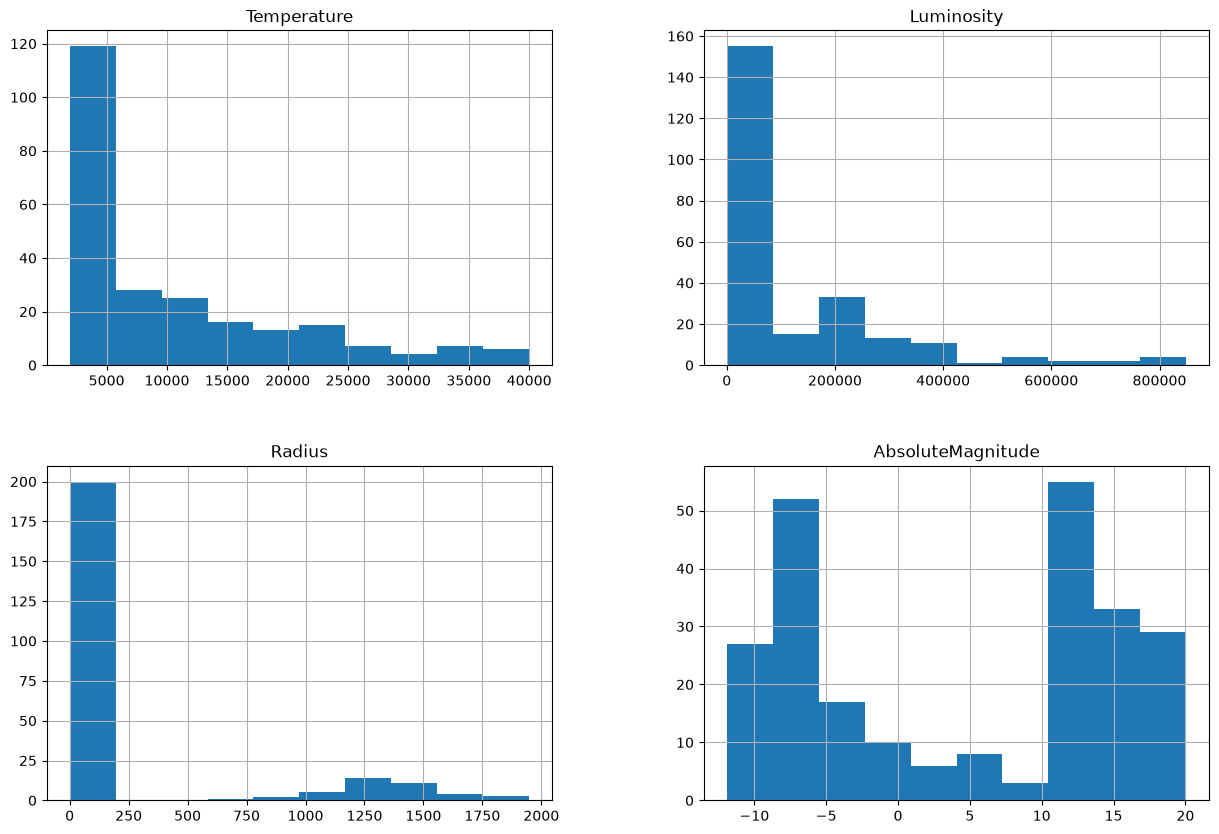

In [176]:
star.hist(figsize = (15,10))

<Axes: xlabel='StarType', ylabel='Temperature'>

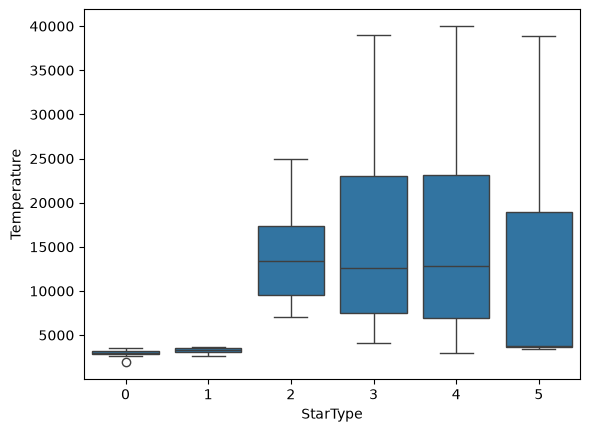

In [177]:
sns.boxplot(data=star, x='StarType', y='Temperature')

<Axes: xlabel='StarType', ylabel='Luminosity'>

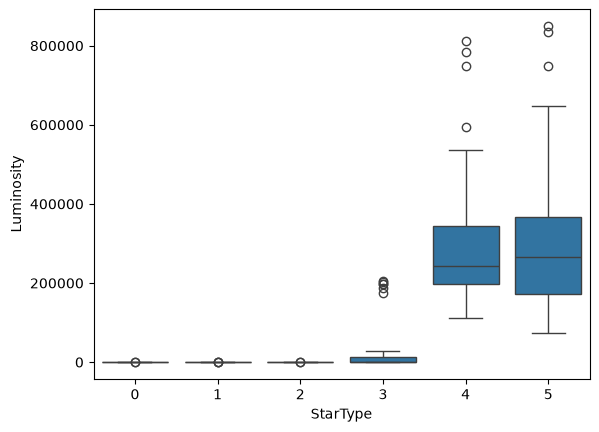

In [178]:
sns.boxplot(data=star, x='StarType', y='Luminosity')

<Axes: xlabel='StarType', ylabel='Radius'>

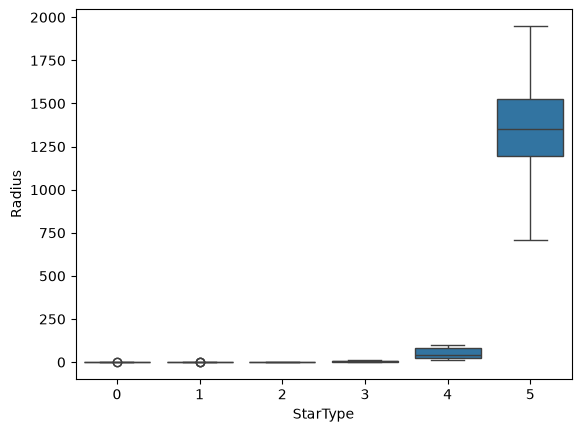

In [179]:
sns.boxplot(data=star, x='StarType', y='Radius')

<Axes: xlabel='StarType', ylabel='AbsoluteMagnitude'>

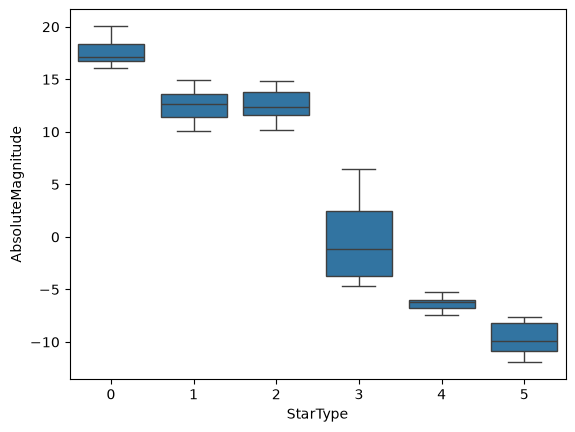

In [180]:
sns.boxplot(data=star, x='StarType', y='AbsoluteMagnitude')

In [181]:
agg_spectral = star.groupby(['StarType', 'SpectralClass'])['StarType'].count().unstack().fillna(0)
agg_spectral

SpectralClass,O,B,A,F,G,K,M
StarType,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,40.0
1,0.0,0.0,0.0,0.0,0.0,0.0,40.0
2,0.0,24.0,7.0,9.0,0.0,0.0,0.0
3,5.0,13.0,10.0,8.0,0.0,4.0,0.0
4,29.0,2.0,0.0,0.0,0.0,0.0,9.0
5,6.0,7.0,2.0,0.0,1.0,2.0,22.0


<Axes: xlabel='StarType', ylabel='Proportion'>

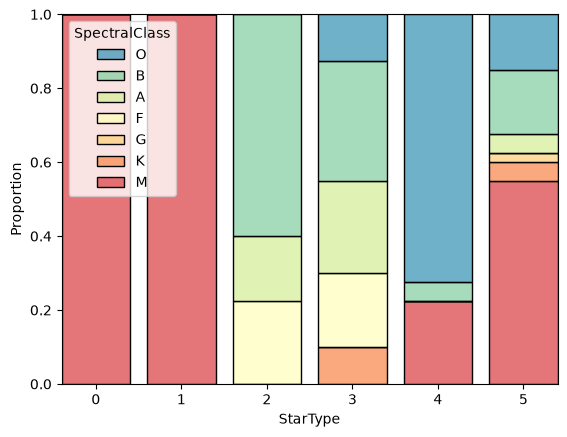

In [189]:
colour_spectral = sns.color_palette("Spectral_r", n_colors=7)

sns.histplot(
    data=star,
    x="StarType", 
    hue="SpectralClass",
    palette= colour_spectral,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarType', ylabel='Proportion'>

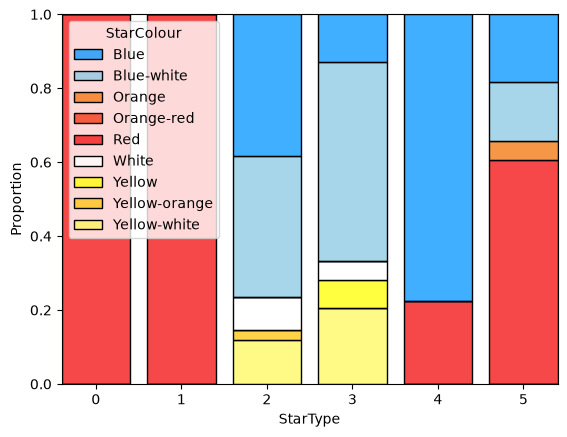

In [183]:
colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

sns.histplot(
    data=star,
    x="StarType", 
    hue="StarColour",
    palette=colour,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarType', ylabel='Proportion'>

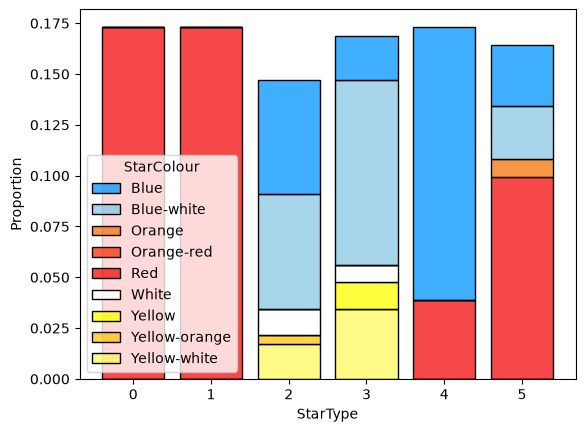

In [184]:
colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

sns.histplot(
    data=star,
    x="StarType", 
    hue="StarColour",
    palette=colour,
    multiple="stack", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

In [185]:
star.groupby('StarColour').count()

,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,SpectralClass
StarColour,,,,,,
Blue,56,56,56,56,56,56
Blue-white,40,40,40,40,40,40
Orange,2,2,2,2,2,2
Red,112,112,112,112,112,112
White,5,5,5,5,5,5
Yellow,3,3,3,3,3,3
Yellow-orange,1,1,1,1,1,1
Yellow-white,12,12,12,12,12,12


In [186]:
star.dtypes

Temperature             int64
Luminosity            float64
Radius                float64
AbsoluteMagnitude     float64
StarType             category
StarColour           category
SpectralClass        category
dtype: object

In [187]:
star

,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,StarColour,SpectralClass
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,NaN,A
238,9235,404940.000000,1112.0000,-11.23,5,NaN,A
